In [ ]:
# Celda 1 — Bootstrap: conecta el notebook con Django para poder usar los modelos y la base de datos.

import os
import sys

sys.path.append(os.path.abspath(".."))  # raíz de backend/
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"

import django
django.setup()

In [ ]:
# Celda 2 — Importa librerías y modelos, carga la serie histórica de deuda de Hacienda
# y muestra los valores de tipo_deuda y moneda, para confirmar cómo filtrar.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_engine.models import (
    CuentaNacionalGasto,
    EstadoOperacionesGobiernoCentral,
    SerieHistoricaDeuda,
    TasaInteresMercado,
)
from data_engine.models.cuenta_nacional_gasto import CLAVE_PIB, MedidaCuentaNacional
from data_engine.models.estado_operaciones_gobierno_central import (
    CONCEPTO_BALANCE,
    CONCEPTO_INTERESES,
    UnidadEstadoOperaciones,
)
from data_engine.models.tasa_interes_mercado import InstrumentoTasa

deuda_cruda = pd.DataFrame(
    SerieHistoricaDeuda.objects.values(
        "anio", "tipo_deuda", "moneda", "monto_millones", "pct_pib", "es_corte_parcial"
    )
)
print("tipo_deuda:", deuda_cruda["tipo_deuda"].unique())
print("moneda:", deuda_cruda["moneda"].unique())

tipo_deuda: ['bruta' 'neta']
moneda: ['clp' 'usd']


In [3]:
# Celda 3 — Arma la tabla base anual (1996-2024): deuda bruta en pesos (Hacienda),
# intereses y balance (DIPRES) y PIB nominal y real (Banco Central), todo en millones de pesos.

def _contiene(serie, texto):
    return serie.astype(str).str.lower().str.contains(texto)


bruta = deuda_cruda[
    _contiene(deuda_cruda["tipo_deuda"], "brut")
    & _contiene(deuda_cruda["moneda"], "clp")
    & ~deuda_cruda["es_corte_parcial"]
].set_index("anio").sort_index()

if bruta.index.duplicated().any():
    raise ValueError("Hay más de una fila por año en la deuda bruta en pesos: revisar el filtro")


def serie_dipres(concepto):
    filas = EstadoOperacionesGobiernoCentral.objects.serie(concepto, UnidadEstadoOperaciones.NOMINAL)
    return pd.Series({f["anio"]: float(f["valor"]) for f in filas if f["valor"] is not None})


def serie_pib(medida):
    filas = CuentaNacionalGasto.objects.serie(CLAVE_PIB, medida)
    return pd.Series({f["anio"]: float(f["valor"]) * 1000 for f in filas})   # miles de millones -> millones


base = pd.DataFrame({
    "deuda": bruta["monto_millones"].astype(float),
    "deuda_pct_pib_hacienda": bruta["pct_pib"].astype(float) * 100,
    "intereses": serie_dipres(CONCEPTO_INTERESES),
    "balance": serie_dipres(CONCEPTO_BALANCE),
    "pib_nominal": serie_pib(MedidaCuentaNacional.NOMINAL),
    "pib_real": serie_pib(MedidaCuentaNacional.REAL),
}).loc[1996:2024]
base.index.name = "anio"
base

,deuda,deuda_pct_pib_hacienda,intereses,balance,pib_nominal,pib_real
anio,,,,,,
1996,4.724475e+06,14.6844,4.331580e+05,6.851750e+05,3.239386e+07,8.163550e+07
1997,4.593961e+06,12.8966,4.309320e+05,7.093360e+05,3.594699e+07,8.766978e+07
1998,4.572509e+06,12.1774,4.455200e+05,1.509400e+05,3.774162e+07,9.133516e+07
1999,5.106574e+06,13.3516,4.692170e+05,-7.904910e+05,3.846179e+07,9.108523e+07
2000,5.549436e+06,13.2113,4.956180e+05,-2.670820e+05,4.221503e+07,9.561365e+07
2001,6.515329e+06,14.4567,5.217850e+05,-2.327470e+05,4.540905e+07,9.862934e+07
2002,7.286297e+06,15.1657,5.423810e+05,-5.748250e+05,4.842896e+07,1.017882e+08
2003,6.650792e+06,12.7166,5.870430e+05,-2.304680e+05,5.289734e+07,1.065959e+08
2004,6.228846e+06,10.3004,5.609770e+05,1.244468e+06,6.039176e+07,1.137104e+08


In [4]:
# Celda 4 — Control de unidades: compara nuestra deuda/PIB e intereses/PIB con lo que publican
# Hacienda y la DIPRES. Las diferencias deben ser de décimas; si son enormes, hay un error de unidades.

intereses_pct_pib_dipres = pd.Series({
    f["anio"]: float(f["valor"])
    for f in EstadoOperacionesGobiernoCentral.objects.serie(CONCEPTO_INTERESES, UnidadEstadoOperaciones.PCT_PIB)
})

control = pd.DataFrame({
    "deuda_nuestra": base["deuda"] / base["pib_nominal"] * 100,
    "deuda_hacienda": base["deuda_pct_pib_hacienda"],
    "intereses_nuestro": base["intereses"] / base["pib_nominal"] * 100,
    "intereses_dipres": intereses_pct_pib_dipres.loc[1996:2024],
}).round(2)
control["dif_deuda"] = control["deuda_nuestra"] - control["deuda_hacienda"]
control["dif_intereses"] = control["intereses_nuestro"] - control["intereses_dipres"]
control

,deuda_nuestra,deuda_hacienda,intereses_nuestro,intereses_dipres,dif_deuda,dif_intereses
1996,14.58,14.68,1.34,1.34,-0.10,0.0
1997,12.78,12.90,1.20,1.20,-0.12,0.0
1998,12.12,12.18,1.18,1.18,-0.06,0.0
1999,13.28,13.35,1.22,1.22,-0.07,0.0
2000,13.15,13.21,1.17,1.17,-0.06,0.0
2001,14.35,14.46,1.15,1.15,-0.11,0.0
2002,15.05,15.17,1.12,1.12,-0.12,0.0
2003,12.57,12.72,1.11,1.11,-0.15,0.0
2004,10.31,10.30,0.93,0.93,0.01,0.0
2005,7.04,7.00,0.81,0.81,0.04,0.0


In [5]:
# Celda 5 — Descomposición de la dinámica de la deuda: cuántos puntos del PIB aportó cada año
# cada factor (intereses, inflación, crecimiento real, déficit primario) y el ajuste no explicado.
# También calcula la tasa efectiva (nominal y real) y r - g.

d = base["deuda"] / base["pib_nominal"] * 100                       # deuda en % del PIB
d_ant = d.shift(1)
gamma = base["pib_nominal"] / base["pib_nominal"].shift(1) - 1      # crecimiento nominal
g = base["pib_real"] / base["pib_real"].shift(1) - 1                # crecimiento real
pi = (1 + gamma) / (1 + g) - 1                                      # inflación del deflactor del PIB
i_ef = base["intereses"] / base["deuda"].shift(1)                   # tasa efectiva nominal
r_ef = (1 + i_ef) / (1 + pi) - 1                                    # tasa efectiva real
pb = (base["balance"] + base["intereses"]) / base["pib_nominal"] * 100   # balance primario, % PIB

dinamica = pd.DataFrame({
    "deuda_pct_pib": d,
    "cambio_deuda": d - d_ant,
    "intereses": i_ef / (1 + gamma) * d_ant,
    "inflacion": -pi * (1 + g) / (1 + gamma) * d_ant,
    "crecimiento_real": -g / (1 + gamma) * d_ant,
    "deficit_primario": -pb,
})
COMPONENTES = ["intereses", "inflacion", "crecimiento_real", "deficit_primario"]
dinamica["ajuste"] = dinamica["cambio_deuda"] - dinamica[COMPONENTES].sum(axis=1)

dinamica["tasa_efectiva_nominal"] = i_ef * 100
dinamica["tasa_efectiva_real"] = r_ef * 100
dinamica["crecimiento_real_pct"] = g * 100
dinamica["r_menos_g"] = dinamica["tasa_efectiva_real"] - dinamica["crecimiento_real_pct"]

dinamica = dinamica.dropna(subset=["cambio_deuda"])
dinamica.round(2)

,deuda_pct_pib,cambio_deuda,intereses,inflacion,crecimiento_real,deficit_primario,ajuste,tasa_efectiva_nominal,tasa_efectiva_real,crecimiento_real_pct,r_menos_g
anio,,,,,,,,,,,
1997,12.78,-1.80,1.20,-0.47,-0.97,-3.17,1.61,9.12,5.60,7.39,-1.79
1998,12.12,-0.66,1.18,-0.10,-0.51,-1.58,0.34,9.70,8.85,4.18,4.67
1999,13.28,1.16,1.22,-0.26,0.03,0.84,-0.67,10.26,7.90,-0.27,8.17
2000,13.15,-0.13,1.17,-0.58,-0.60,-0.54,0.42,9.71,4.92,4.97,-0.05
2001,14.35,1.20,1.15,-0.54,-0.39,-0.64,1.61,9.40,4.92,3.15,1.76
2002,15.05,0.70,1.12,-0.46,-0.43,0.07,0.41,8.32,4.82,3.20,1.62
2003,12.57,-2.47,1.11,-0.62,-0.65,-0.67,-1.64,8.06,3.60,4.72,-1.12
2004,10.31,-2.26,0.93,-0.83,-0.74,-2.99,1.36,8.43,1.32,6.67,-5.36
2005,7.04,-3.27,0.81,-0.69,-0.53,-5.23,2.36,8.93,1.69,5.84,-4.15


In [6]:
# Celda 6 — Suma las contribuciones por etapas históricas, para ver qué movió la deuda en cada período.

ETAPAS = {
    "1997-2007 desendeudamiento": (1997, 2007),
    "2008-2012 crisis y rebote": (2008, 2012),
    "2013-2019 bajo crecimiento": (2013, 2019),
    "2020-2024 pandemia y después": (2020, 2024),
    "1997-2024 total": (1997, 2024),
}
acumulado = pd.DataFrame({
    nombre: dinamica.loc[desde:hasta, ["cambio_deuda"] + COMPONENTES + ["ajuste"]].sum()
    for nombre, (desde, hasta) in ETAPAS.items()
}).T.round(1)
acumulado

,cambio_deuda,intereses,inflacion,crecimiento_real,deficit_primario,ajuste
1997-2007 desendeudamiento,-10.7,11.1,-5.6,-5.4,-30.3,19.4
2008-2012 crisis y rebote,8.0,2.6,-1.0,-1.5,-3.5,11.5
2013-2019 bajo crecimiento,16.4,5.2,-4.4,-2.5,9.2,8.9
2020-2024 pandemia y después,13.5,5.1,-12.1,-3.3,14.0,9.8
1997-2024 total,27.2,24.0,-23.1,-12.7,-10.6,49.6


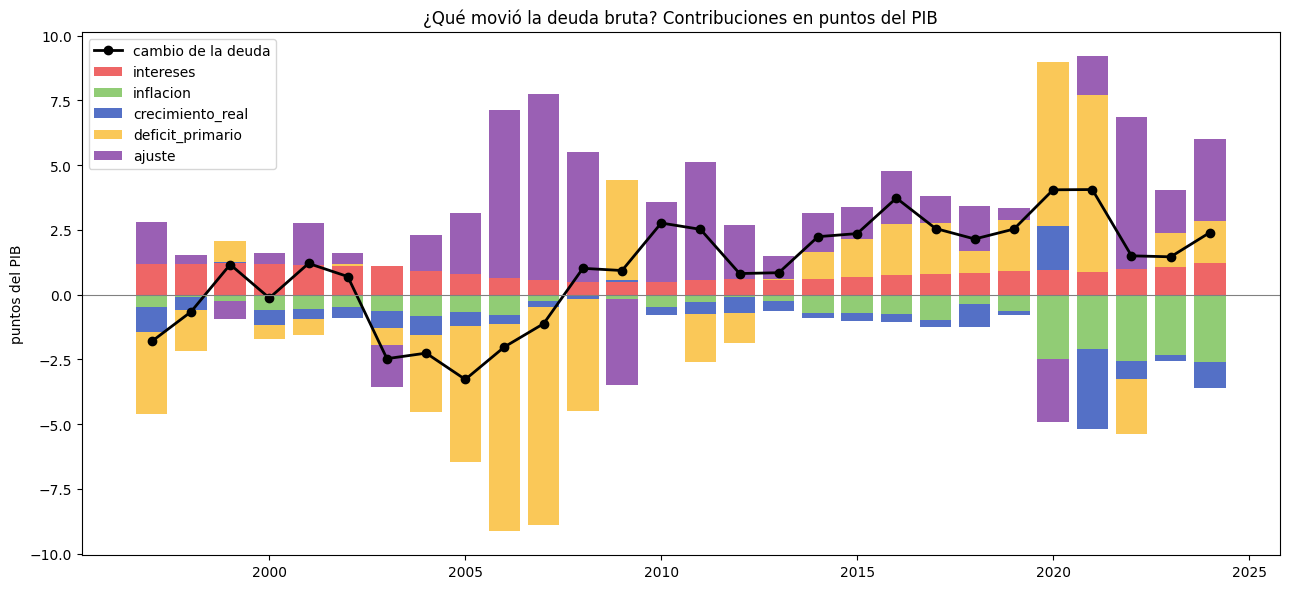

In [7]:
# Celda 7 — Gráfico de barras apiladas: la contribución de cada factor por año,
# con una línea negra para el cambio total de la deuda.

fig, ax = plt.subplots(figsize=(13, 6))
colores = {
    "intereses": "#ee6666", "inflacion": "#91cc75", "crecimiento_real": "#5470c6",
    "deficit_primario": "#fac858", "ajuste": "#9a60b4",
}
positivo = np.zeros(len(dinamica))
negativo = np.zeros(len(dinamica))
for col, color in colores.items():
    valores = dinamica[col].to_numpy()
    abajo = np.where(valores >= 0, positivo, negativo)
    ax.bar(dinamica.index, valores, bottom=abajo, color=color, label=col)
    positivo += np.where(valores >= 0, valores, 0)
    negativo += np.where(valores < 0, valores, 0)
ax.plot(dinamica.index, dinamica["cambio_deuda"], "k-o", label="cambio de la deuda", linewidth=2)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("¿Qué movió la deuda bruta? Contribuciones en puntos del PIB")
ax.set_ylabel("puntos del PIB")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

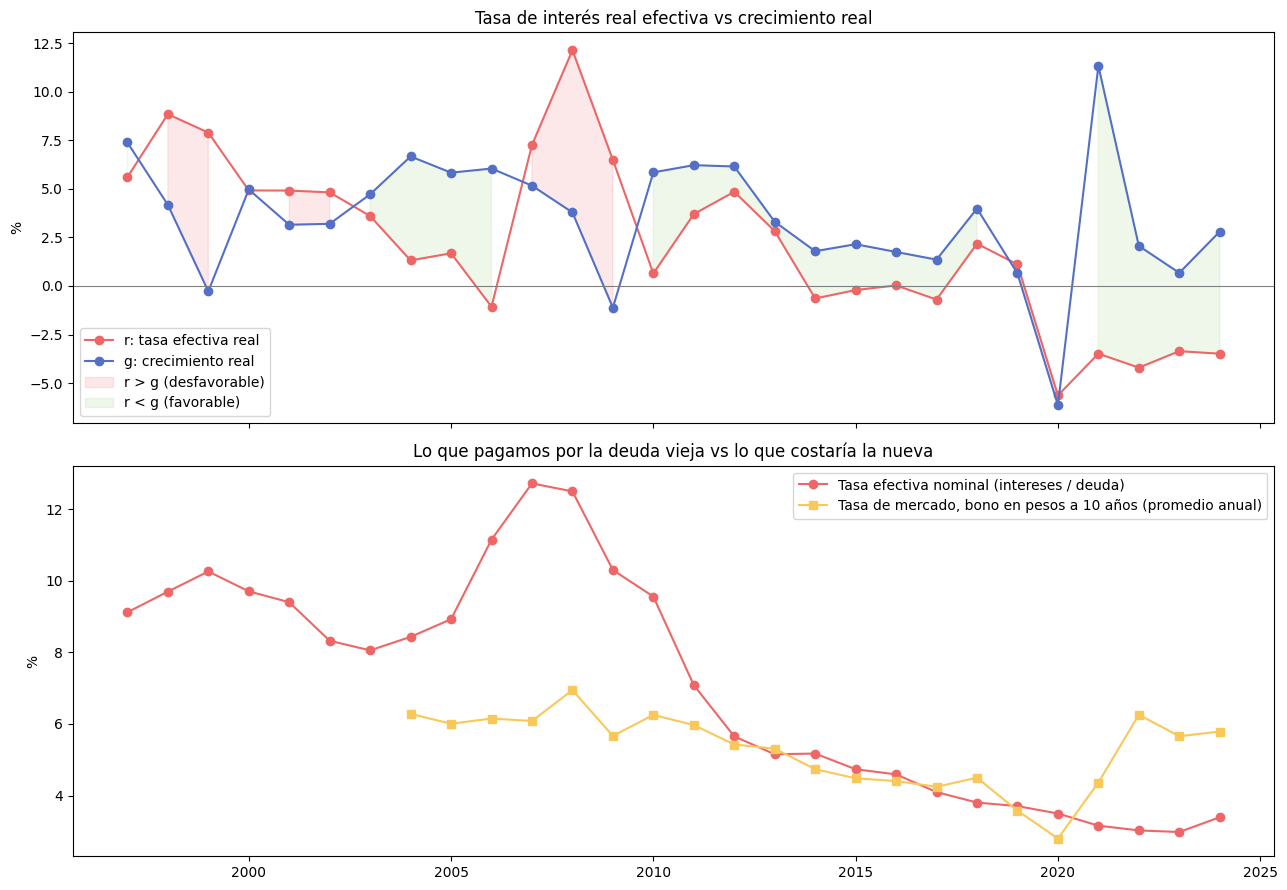

In [8]:
# Celda 8 — Dos gráficos: (1) tasa real efectiva vs crecimiento real, marcando los años r > g y r < g;
# (2) la tasa efectiva que pagamos por la deuda vieja vs la tasa de mercado del bono en pesos a 10 años.

tasa_mercado_10a = pd.DataFrame(
    TasaInteresMercado.objects.serie(InstrumentoTasa.BONO_PESOS, 10)
)
tasa_mercado_10a["anio"] = pd.to_datetime(tasa_mercado_10a["fecha"]).dt.year
tasa_mercado_10a = tasa_mercado_10a.groupby("anio")["valor"].apply(lambda v: v.astype(float).mean())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

ax1.plot(dinamica.index, dinamica["tasa_efectiva_real"], "-o", color="#ee6666", label="r: tasa efectiva real")
ax1.plot(dinamica.index, dinamica["crecimiento_real_pct"], "-o", color="#5470c6", label="g: crecimiento real")
ax1.fill_between(dinamica.index, dinamica["tasa_efectiva_real"], dinamica["crecimiento_real_pct"],
                 where=dinamica["r_menos_g"] > 0, color="#ee6666", alpha=0.15, label="r > g (desfavorable)")
ax1.fill_between(dinamica.index, dinamica["tasa_efectiva_real"], dinamica["crecimiento_real_pct"],
                 where=dinamica["r_menos_g"] <= 0, color="#91cc75", alpha=0.15, label="r < g (favorable)")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set_title("Tasa de interés real efectiva vs crecimiento real")
ax1.set_ylabel("%")
ax1.legend()

ax2.plot(dinamica.index, dinamica["tasa_efectiva_nominal"], "-o", color="#ee6666",
         label="Tasa efectiva nominal (intereses / deuda)")
ax2.plot(tasa_mercado_10a.loc[1997:2024].index, tasa_mercado_10a.loc[1997:2024], "-s", color="#fac858",
         label="Tasa de mercado, bono en pesos a 10 años (promedio anual)")
ax2.set_title("Lo que pagamos por la deuda vieja vs lo que costaría la nueva")
ax2.set_ylabel("%")
ax2.legend()

plt.tight_layout()
plt.show()